# NLP Assignment 2 — Word representations for GoEmotions
**Phase 2 · Member 1 · Part A (count-based representations) and Part D (packaging)**

Member 1: *add name / ID here* · Course: *add course / section* · Date: *add date*

**How Phase 2 is split.** The Phase 2 work is divided between two team members, one notebook each. Each notebook starts from the Phase 1 output and runs **on its own**: it does not need any variable from `03b_embeddings_and_probing.ipynb`, and the two share only the code in `src/` (so they cannot disagree on the corpus, the tokens or the hyper-parameters).

| Notebook | Member | Parts | Sections |
|---|---|---|---|
| **`03a_count_based_and_packaging.ipynb` (this notebook)** | 1 | **A** and **D** | A1 – A4 Bag of Words, TF-IDF, n-grams, hand-worked example · D1 – D2 saving every model, the `vectorize()` interface |
| `03b_embeddings_and_probing.ipynb` | 2 | **B** and **C** | B1 – B4 Word2Vec (CBOW, Skip-gram), fastText · C1 – C4 neighbours, similarities, analogy, count-based vs learned |

**Topic recap.** Fine-grained emotion detection on Reddit comments (GoEmotions: 54,263 comments, 28 emotion labels). Phase 1 produced a cleaned corpus; here we turn that corpus into numbers a model can use, and compare the ways of doing it.

**Decisions that apply to everything below** (they keep the comparison fair, as the brief requires):

1. **One corpus.** Every representation is built from the Phase 1 column `text_clean`. We do *not* clean anything differently.
2. **Fitted on the training split only.** Vocabulary, IDF values and embeddings come from the 43,410 training comments. Validation and test comments are only ever *transformed*, so Phase 3 can be evaluated without leakage.
3. **Phase 1 tokens are kept as they are.** `text_clean` is already tokenised (words separated by single spaces), so every vectorizer simply splits on whitespace. A library tokenizer would silently drop one-letter words such as `i`, signal tokens such as `!` and `?`, placeholders such as `<name>` and emoji, all of which Phase 1 deliberately kept.
4. **Identical hyper-parameters** for CBOW, Skip-gram and fastText; only the training scheme (and, for fastText, the sub-word information) differs.
5. **Deterministic.** Fixed seed, one worker thread and a process-independent hash: re-running gives the same vectors.

All reusable code lives in `src/` (`representations.py`, `build_representations.py`, `vectorize.py`); this notebook calls it, so it shows exactly what the scripts do.

In [1]:
import sys, re, time, json, math, subprocess, collections, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

def find_project_root():
    """Locate the folder that contains src/cleaning.py, wherever Jupyter was started."""
    start = Path.cwd().resolve()
    for base in (start, *start.parents):
        for candidate in (base, base / "goemotions-nlp"):
            if (candidate / "src" / "cleaning.py").exists():
                return candidate
    raise FileNotFoundError(
        f"Could not find the project's src/ folder from {start}.\n"
        "This notebook needs the whole project, not just the .ipynb file: clone the repository "
        "(or unzip goemotions-nlp.zip) and open notebooks/03a_count_based_and_packaging.ipynb from inside it "
        "(on Colab/Kaggle, clone or upload the project, then %cd goemotions-nlp/notebooks first)."
    )

ROOT = find_project_root()
sys.path.insert(0, str(ROOT))

from src import representations as R

def say(text):
    """Show a sentence (with numbers computed by the code above it) as formatted text."""
    display(Markdown(text))

if not R.CLEAN_CSV.exists():
    print("Phase 1 output not found - running  python -m src.run_cleaning  ...")
    subprocess.run([sys.executable, "-m", "src.run_cleaning"], cwd=ROOT, check=True)

df = R.load_clean_corpus()
train = df[df["split"] == R.FIT_SPLIT]
texts = train["text_clean"].tolist()
sentences = R.tokenize_corpus(texts)
word_counts = collections.Counter(w for s in sentences for w in s)
N_DOCS, N_TOKENS = len(texts), sum(word_counts.values())

summary = df.groupby("split").agg(comments=("text_clean", "size"),
                                  tokens=("text_clean", lambda s: s.str.split().str.len().sum()))
summary.loc["fitted on 'train'"] = ["", ""]
display(summary.loc[["train", "validation", "test"]])
say(f"**Corpus used to fit every representation:** the *{R.FIT_SPLIT}* split — {N_DOCS:,} comments, "
    f"{N_TOKENS:,} tokens, {len(word_counts):,} distinct words, {N_TOKENS / N_DOCS:.1f} tokens per comment on average.")

,comments,tokens
split,,
train,43410,380557
validation,5426,47457
test,5427,47255


**Corpus used to fit every representation:** the *train* split — 43,410 comments, 380,557 tokens, 20,026 distinct words, 8.8 tokens per comment on average.

---
# Part A — Count-based representations

A count-based representation describes a document by *which words it contains* (and how often). It has one dimension per vocabulary entry, so the vectors are long but almost entirely zeros.

## A1  Bag of Words

A **bag of words** keeps only how many times each word occurs in a comment and forgets the order. Stacking one such count vector per comment gives the **document–term matrix** (rows = comments, columns = vocabulary). We build it with scikit-learn's `CountVectorizer`, told to split on whitespace and not to lower-case again (Phase 1 already did).

In [2]:
bow = R.make_count_vectorizer()
X_bow = bow.fit_transform(texts)

n_docs, n_terms = X_bow.shape
n_cells = n_docs * n_terms
sparsity_bow = R.sparsity_pct(X_bow)
sparse_mb = (X_bow.data.nbytes + X_bow.indices.nbytes + X_bow.indptr.nbytes) / 1e6
dense_gb = n_cells * X_bow.dtype.itemsize / 1e9

display(pd.DataFrame({
    "shape (comments × words)": [f"{n_docs:,} × {n_terms:,}"],
    "cells": [f"{n_cells:,}"],
    "non-zero cells": [f"{X_bow.nnz:,}"],
    "zero cells (sparsity)": [f"{sparsity_bow:.4f} %"],
    "stored sparse": [f"{sparse_mb:.1f} MB"],
    "if stored dense": [f"{dense_gb:.1f} GB"],
}, index=["Bag of Words"]).T)

i = 0
row = X_bow[i]
vocab_terms = bow.get_feature_names_out()
print("comment      :", texts[i])
print("non-zero cols:", {vocab_terms[j]: int(c) for j, c in zip(row.indices, row.data)})

top = pd.Series(np.asarray(X_bow.sum(axis=0)).ravel(), index=vocab_terms).sort_values(ascending=False)
print("\n15 most frequent words in the matrix (total count):")
display(top.head(15).to_frame("count").T)

,Bag of Words
shape (comments × words),"43,410 × 20,026"
cells,"869,328,660"
non-zero cells,"356,917"
zero cells (sparsity),99.9589 %
stored sparse,3.0 MB
if stored dense,3.5 GB


comment      : my favourite food anything i not cook myself
non-zero cols: {'my': 1, 'favourite': 1, 'food': 1, 'anything': 1, 'i': 1, 'not': 1, 'cook': 1, 'myself': 1}

15 most frequent words in the matrix (total count):


,i,you,not,<name>,!,?,<num>,my,get,so,like,just,...,what,would
count,23946,11553,10594,7680,7185,5132,5026,3781,3662,3502,3452,3430,2945,2773,2744


In [3]:
say(f"**Result.** The Bag-of-Words matrix is **{n_docs:,} × {n_terms:,}**; only {X_bow.nnz:,} of its {n_cells:,} cells are non-zero, "
    f"so it is **{sparsity_bow:.3f} % zeros**. A typical comment uses only {X_bow.nnz / n_docs:.1f} distinct words out of {n_terms:,}. "
    f"Stored as a sparse matrix it needs {sparse_mb:.1f} MB; stored densely it would need about {dense_gb:.1f} GB, which is why "
    f"count-based features are always kept in a sparse format.")

**Result.** The Bag-of-Words matrix is **43,410 × 20,026**; only 356,917 of its 869,328,660 cells are non-zero, so it is **99.959 % zeros**. A typical comment uses only 8.2 distinct words out of 20,026. Stored as a sparse matrix it needs 3.0 MB; stored densely it would need about 3.5 GB, which is why count-based features are always kept in a sparse format.

## A2  TF-IDF

Raw counts treat every word as equally informative, so `not` or `i` (present in a large share of all comments) outweighs a distinctive word that appears once. **TF-IDF** re-weights each count:

$$\text{tf-idf}(t,d)=\text{tf}(t,d)\times \text{idf}(t),\qquad \text{idf}(t)=\ln\frac{1+N}{1+\text{df}(t)}+1$$

* **tf(t, d)** — how often term *t* occurs in document *d* (the Bag-of-Words count).
* **df(t)** — in how many of the *N* documents *t* occurs at least once. 
* **idf(t)** — large when *t* is rare, small when it is everywhere. This is scikit-learn's *smoothed* version; the textbook version is simply ln(N / df).
* Each row is finally divided by its own length (L2 norm), so a long comment does not get bigger numbers than a short one.

The next cell builds the matrix over the same corpus and shows one real comment with a few high-weight and several low-weight words.

In [4]:
tfidf = R.make_tfidf_vectorizer()
X_tfidf = tfidf.fit_transform(texts)
assert X_tfidf.shape == X_bow.shape

terms = np.array(tfidf.get_feature_names_out())
term_index = {t: j for j, t in enumerate(terms)}
doc_freq = np.asarray((X_bow > 0).sum(axis=0)).ravel()
idf_textbook = np.log(N_DOCS / doc_freq)
idf_sklearn = tfidf.idf_

order = np.argsort(idf_sklearn)
extremes = pd.DataFrame({
    "df": doc_freq[order], "df %": (100 * doc_freq[order] / N_DOCS).round(2),
    "idf (textbook)": idf_textbook[order].round(2), "idf (sklearn)": idf_sklearn[order].round(2)},
    index=terms[order])
print("Lowest idf = the most common words:");  display(extremes.head(8).T)
print("Highest idf = words seen in only one comment (a few of the", int((doc_freq == 1).sum()), "):"); display(extremes.tail(4).T)

rng = np.random.default_rng(R.SEED)
example = None
for i in rng.permutation(N_DOCS):
    toks = sentences[i]
    dfs = [doc_freq[term_index[t]] for t in set(toks)]
    if 8 <= len(toks) <= 12 and max(dfs) / N_DOCS >= 0.05 and min(dfs) <= 5:
        example = i
        break

tokens = list(dict.fromkeys(sentences[example]))
row = X_tfidf[example]
weights = {terms[j]: w for j, w in zip(row.indices, row.data)}
table = pd.DataFrame({
    "tf": [sentences[example].count(t) for t in tokens],
    "df": [doc_freq[term_index[t]] for t in tokens],
    "idf (textbook)": [round(idf_textbook[term_index[t]], 2) for t in tokens],
    "idf (sklearn)": [round(idf_sklearn[term_index[t]], 2) for t in tokens],
    "tf-idf weight": [round(weights[t], 3) for t in tokens]}, index=tokens).sort_values("tf-idf weight", ascending=False)
print("\nraw comment   :", train.iloc[example]["text"])
print("cleaned (A2)  :", texts[example])
display(table)
print("row length (L2 norm of the weights):", round(float(np.linalg.norm(row.data)), 3))

Lowest idf = the most common words:


,i,not,you,<name>,!,?,<num>,get
df,17355.00,9538.00,9275.00,6059.00,6020.00,4581.00,3682.00,3483.00
df %,39.98,21.97,21.37,13.96,13.87,10.55,8.48,8.02
idf (textbook),0.92,1.52,1.54,1.97,1.98,2.25,2.47,2.52
idf (sklearn),1.92,2.52,2.54,2.97,2.98,3.25,3.47,3.52


Highest idf = words seen in only one comment (a few of the 9961 ):


,🦵,aaf,🧡,aaditi
df,1.00,1.00,1.00,1.00
df %,0.00,0.00,0.00,0.00
idf (textbook),10.68,10.68,10.68,10.68
idf (sklearn),10.99,10.99,10.99,10.99



raw comment   : I would say they do because it was a horrible accident but they were also in the wrong. The military tried to get them to disperse they didnt.
cleaned (A2)  : i would say horrible accident also wrong military try get disperse not


,tf,df,idf (textbook),idf (sklearn),tf-idf weight
disperse,1,1,10.68,10.99,0.521
military,1,29,7.31,8.28,0.393
accident,1,31,7.24,8.21,0.390
horrible,1,124,5.86,6.85,0.325
wrong,1,370,4.76,5.76,0.273
also,1,687,4.15,5.14,0.244
try,1,840,3.95,4.94,0.235
say,1,1453,3.40,4.40,0.209
would,1,2579,2.82,3.82,0.181
get,1,3483,2.52,3.52,0.167


row length (L2 norm of the weights): 1.0


**Reading the table.**

* **High weight — rare, specific words.** A word that few other comments use (small `df`, so large idf) dominates the comment's vector. It is the part of the comment that tells it apart from the rest of the corpus, which is what a classifier can use.
* **Weight pushed down — common words.** Words that occur in a large share of all comments (`i`, `not`, `you`, and signal tokens such as `!`) have a small idf, so even when they occur often in the comment they contribute little. TF-IDF therefore down-weights exactly the words that carry the least information about *this* comment.
* **"Toward zero" needs a caveat.** With the textbook formula ln(N/df) a word present in *every* document would get exactly 0. In this corpus nothing is that common (the commonest word, `i`, is in about 40 % of the comments, because Phase 1 already removed stop words), so no weight is literally zero; the common words are only *relatively* small. scikit-learn also adds `+1` to the idf so that a word seen everywhere keeps a small positive weight instead of vanishing. Section A4 uses a tiny corpus in which one word *is* in every document, so you can see both formulas side by side.

## A3  N-grams

A unigram model cannot tell `not good` from `good`: the negation and the word are counted separately. **N-grams** add short runs of consecutive words as extra features: bigrams (2 words) and trigrams (3 words). The price is a much bigger vocabulary. We rebuild the Bag of Words with `ngram_range = (1,1)`, `(1,2)` and `(1,3)`, with no pruning (`min_df=1`) and with pruning (`min_df=2` and `5`, which drop n-grams seen in fewer than 2 or 5 comments).

,n-grams,min_df,features,non-zeros,sparsity %,non-zeros / comment,sparse size MB
0,unigrams,1,20026,356917,99.9589,8.2,3.0
1,unigrams,2,10065,346956,99.9206,8.0,2.9
2,unigrams,5,5122,333903,99.8498,7.7,2.8
3,uni + bigrams,1,199440,691992,99.9920,15.9,5.7
4,uni + bigrams,2,40326,532878,99.9696,12.3,4.4
5,uni + bigrams,5,12565,463417,99.9150,10.7,3.9
6,uni + bi + trigrams,1,458858,985445,99.9951,22.7,8.1
7,uni + bi + trigrams,2,53138,579725,99.9749,13.4,4.8
8,uni + bi + trigrams,5,14408,484093,99.9226,11.2,4.0


,1-grams only,2-grams only,3-grams only
distinct features (min_df=1),20026,179414,259418


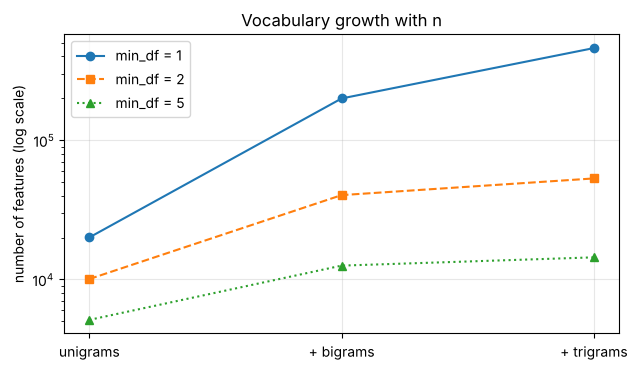

most frequent bigrams: 'i not' (2,239), 'i think' (1,038), 'thank you' (978), 'i love' (939), 'i would' (937), 'you not' (750), 'i just' (646), '<num> <num>' (644), '! i' (575), '<name> <name>' (556)


most frequent trigrams: 'i not know' (249), 'i not think' (219), 'thank you !' (183), '<num> <num> <num>' (174), 'i feel like' (146), 'i would love' (141), '<num> year old' (119), 'i think i' (118), 'i hope you' (116), 'i think you' (106)


In [5]:
rows = []
for ng, label in [((1, 1), "unigrams"), ((1, 2), "uni + bigrams"), ((1, 3), "uni + bi + trigrams")]:
    for min_df in (1, 2, 5):
        v = R.make_count_vectorizer(ngram_range=ng, min_df=min_df)
        X = v.fit_transform(texts)
        rows.append({"n-grams": label, "min_df": min_df, "features": X.shape[1], "non-zeros": X.nnz,
                     "sparsity %": round(R.sparsity_pct(X), 4), "non-zeros / comment": round(X.nnz / X.shape[0], 1),
                     "sparse size MB": round((X.data.nbytes + X.indices.nbytes + X.indptr.nbytes) / 1e6, 1)})
growth = pd.DataFrame(rows)
display(growth)

pure = {}
for n in (1, 2, 3):
    pure[f"{n}-grams only"] = len(R.make_count_vectorizer(ngram_range=(n, n)).fit(texts).vocabulary_)
display(pd.Series(pure, name="distinct features (min_df=1)").to_frame().T)

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for min_df, style in [(1, "o-"), (2, "s--"), (5, "^:")]:
    sub = growth[growth.min_df == min_df]
    ax.plot([1, 2, 3], sub["features"], style, label=f"min_df = {min_df}")
ax.set_yscale("log"); ax.set_xticks([1, 2, 3], ["unigrams", "+ bigrams", "+ trigrams"])
ax.set_ylabel("number of features (log scale)"); ax.set_title("Vocabulary growth with n"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

for n, name in [(2, "bigrams"), (3, "trigrams")]:
    v = R.make_count_vectorizer(ngram_range=(n, n)); Xn = v.fit_transform(texts)
    counts = pd.Series(np.asarray(Xn.sum(axis=0)).ravel(), index=v.get_feature_names_out()).sort_values(ascending=False)
    print(f"most frequent {name}:", ", ".join(f"'{g}' ({c:,})" for g, c in counts.head(10).items()))

In [6]:
g = growth.set_index(["n-grams", "min_df"])
uni, bi, tri = (g.loc[(k, 1), "features"] for k in ["unigrams", "uni + bigrams", "uni + bi + trigrams"])
say(f"**Result.** Without pruning, the vocabulary grows from **{uni:,}** unigrams to **{bi:,}** features with bigrams (×{bi/uni:.1f}) "
    f"and **{tri:,}** with trigrams (×{tri/uni:.1f}). With `min_df=2` the trigram model shrinks to {g.loc[('uni + bi + trigrams', 2), 'features']:,} features "
    f"({100 * (1 - g.loc[('uni + bi + trigrams', 2), 'features'] / tri):.0f} % fewer), because most n-grams occur in a single comment.")

**Result.** Without pruning, the vocabulary grows from **20,026** unigrams to **199,440** features with bigrams (×10.0) and **458,858** with trigrams (×22.9). With `min_df=2` the trigram model shrinks to 53,138 features (88 % fewer), because most n-grams occur in a single comment.

**Sparsity trade-off.**

* **The matrix gets sparser, but each row gets fuller.** The percentage of zeros rises with n because the number of columns explodes much faster than the number of entries. But a comment of *k* tokens contains *k* unigrams, *k−1* bigrams and *k−2* trigrams, so the number of **non-zeros per comment** grows too. Memory follows the number of non-zeros, not the percentage of zeros.
* **Most new features are one-offs.** The unpruned bigram and trigram vocabularies are dominated by combinations seen once. A feature seen once cannot help a model generalise (it can only memorise a single training comment), and in a test comment it will rarely reappear. This is why `min_df` pruning is standard: it removes most of the columns and costs few non-zeros.
* **What we gain.** Bigrams recover a little word order, for example negation (`not good`) and polite formulas (`thank you`), which a bag of unigrams scatters. Once rare n-grams are pruned, trigrams add far fewer features than bigrams do (compare the three `min_df=2` rows of the table), because our comments are short (about 9 tokens after cleaning) and rarely repeat the same three-word sequence.
* **Our choice for Phase 3:** the saved TF-IDF vectorizer uses unigrams + bigrams with `min_df=3` (a compact vocabulary that keeps the useful bigrams).

## A4  Hand-worked numerical example

To be sure we understand what the library does, we compute one TF-IDF weight and one bigram **by hand** on a tiny sub-sample, then compare with scikit-learn. The four documents are real short comments from the training set (their Phase 1 `text_clean`), chosen so that the word `good` occurs in all four, the bigram `not good` in three, and one comment repeats a word (`sound` twice).

The "by hand" part uses nothing but `math.log`, counting, and the formulas above, and prints every step so it can be copied onto paper (the assignment asks for a scanned copy of the handwritten version; the printout below is the worksheet to copy from).

In [7]:
toy_ids = ["eezjbs8", "edk3yt2", "ed4qthk", "ed3zhy2"]
toy = df.set_index("comment_id").loc[toy_ids, ["text", "text_clean"]]
toy.index = [f"d{k}" for k in range(1, 5)]
display(toy)

toy_docs = toy["text_clean"].tolist()
toy_tokens = [d.split() for d in toy_docs]
N_TOY = len(toy_docs)
print("N =", N_TOY, "documents")

,text,text_clean
d1,Uhhhhhhhhh well that's not good,uhh well not good
d2,ESPN and sports is not a good combination.,espn sport not good combination
d3,This was so good I groaned audibly.,so good i groan audibly
d4,"Not a good sound, a glorious sound.",not good sound glorious sound


N = 4 documents


In [8]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

def tfidf_by_hand(term, doc_no, docs):
    """Print each step of the scikit-learn TF-IDF weight of `term` in document number `doc_no` (1-based).
    `docs` is a list of token lists (words for a unigram weight, 'w1 w2' strings for a bigram weight)."""
    N = len(docs)
    d = docs[doc_no - 1]
    df_of = lambda t: sum(t in doc for doc in docs)
    idf_of = lambda t: math.log((1 + N) / (1 + df_of(t))) + 1

    tf = d.count(term)
    print(f"term = '{term}', document d{doc_no} = {d}")
    print(f"1) tf       : '{term}' occurs {tf} time(s) in d{doc_no}  ->  tf = {tf}")
    print(f"2) df       : '{term}' occurs in {df_of(term)} of the N = {N} documents  ->  df = {df_of(term)}")
    print(f"3) idf      : ln((1+N)/(1+df)) + 1 = ln({1+N}/{1+df_of(term)}) + 1 = {math.log((1+N)/(1+df_of(term))):.4f} + 1 = {idf_of(term):.4f}")
    print(f"             (the textbook ln(N/df) = ln({N}/{df_of(term)}) = {math.log(N/df_of(term)):.4f})")
    print(f"4) raw      : tf × idf = {tf} × {idf_of(term):.4f} = {tf * idf_of(term):.4f}")

    uniq = list(dict.fromkeys(d))
    raw = {t: d.count(t) * idf_of(t) for t in uniq}
    print(f"5) the same for every term of d{doc_no}:")
    for t in uniq:
        print(f"     {t:16s} tf={d.count(t)}  df={df_of(t)}  idf={idf_of(t):.4f}  raw={raw[t]:.4f}")
    sq = sum(v * v for v in raw.values())
    norm = math.sqrt(sq)
    print(f"6) L2 norm  : sqrt({' + '.join(f'{v:.4f}²' for v in raw.values())}) = sqrt({sq:.4f}) = {norm:.4f}")
    weight = raw[term] / norm
    print(f"7) weight   : raw / norm = {raw[term]:.4f} / {norm:.4f} = {weight:.4f}")
    return weight

by_hand = tfidf_by_hand("sound", 4, toy_tokens)

lib = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False)
X_toy = lib.fit_transform(toy_docs)
library_value = X_toy[3, lib.vocabulary_["sound"]]
print(f"\nscikit-learn TfidfVectorizer gives {library_value:.4f}   ->   matches the hand calculation: {math.isclose(by_hand, library_value, rel_tol=1e-9)}")
assert math.isclose(by_hand, library_value, rel_tol=1e-9)

term = 'sound', document d4 = ['not', 'good', 'sound', 'glorious', 'sound']
1) tf       : 'sound' occurs 2 time(s) in d4  ->  tf = 2
2) df       : 'sound' occurs in 1 of the N = 4 documents  ->  df = 1
3) idf      : ln((1+N)/(1+df)) + 1 = ln(5/2) + 1 = 0.9163 + 1 = 1.9163
             (the textbook ln(N/df) = ln(4/1) = 1.3863)
4) raw      : tf × idf = 2 × 1.9163 = 3.8326
5) the same for every term of d4:
     not              tf=1  df=3  idf=1.2231  raw=1.2231
     good             tf=1  df=4  idf=1.0000  raw=1.0000
     sound            tf=2  df=1  idf=1.9163  raw=3.8326
     glorious         tf=1  df=1  idf=1.9163  raw=1.9163
6) L2 norm  : sqrt(1.2231² + 1.0000² + 3.8326² + 1.9163²) = sqrt(20.8569) = 4.5669
7) weight   : raw / norm = 3.8326 / 4.5669 = 0.8392

scikit-learn TfidfVectorizer gives 0.8392   ->   matches the hand calculation: True


In [9]:
t = "good"
print(f"'{t}' occurs in {sum(t in d for d in toy_tokens)} of {N_TOY} documents:  textbook ln(N/df) = ln({N_TOY}/{N_TOY}) = {math.log(1):.1f},"
      f"  scikit-learn ln((1+N)/(1+df)) + 1 = ln({1+N_TOY}/{1+N_TOY}) + 1 = {math.log(1) + 1:.1f}")
print(f"its weight in d4 is {X_toy[3, lib.vocabulary_[t]]:.4f}, against {X_toy[3, lib.vocabulary_['sound']]:.4f} for 'sound'")

'good' occurs in 4 of 4 documents:  textbook ln(N/df) = ln(4/4) = 0.0,  scikit-learn ln((1+N)/(1+df)) + 1 = ln(5/5) + 1 = 1.0
its weight in d4 is 0.2190, against 0.8392 for 'sound'


In [10]:
def bigrams(tokens):
    return [f"{a} {b}" for a, b in zip(tokens, tokens[1:])]

toy_bigrams = [bigrams(t) for t in toy_tokens]
for k, b in enumerate(toy_bigrams, 1):
    print(f"d{k} bigrams: {b}")

target = "not good"
by_hand_counts = [b.count(target) for b in toy_bigrams]
print(f"\ncount of the bigram '{target}' in d1..d4 by hand: {by_hand_counts}")

cv2 = CountVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(2, 2))
C2 = cv2.fit_transform(toy_docs)
library_counts = C2[:, cv2.vocabulary_[target]].toarray().ravel().tolist()
print(f"CountVectorizer(ngram_range=(2,2)) gives                  : {library_counts}   ->   matches: {by_hand_counts == library_counts}")
assert by_hand_counts == library_counts

print("\n--- and its TF-IDF weight in d4, with the same seven steps (now the 'terms' are bigrams):\n")
by_hand_bi = tfidf_by_hand(target, 4, toy_bigrams)
lib2 = TfidfVectorizer(tokenizer=str.split, token_pattern=None, lowercase=False, ngram_range=(2, 2))
X_toy2 = lib2.fit_transform(toy_docs)
library_bi = X_toy2[3, lib2.vocabulary_[target]]
print(f"\nscikit-learn TfidfVectorizer(ngram_range=(2,2)) gives {library_bi:.4f}   ->   matches: {math.isclose(by_hand_bi, library_bi, rel_tol=1e-9)}")
assert math.isclose(by_hand_bi, library_bi, rel_tol=1e-9)

d1 bigrams: ['uhh well', 'well not', 'not good']
d2 bigrams: ['espn sport', 'sport not', 'not good', 'good combination']
d3 bigrams: ['so good', 'good i', 'i groan', 'groan audibly']
d4 bigrams: ['not good', 'good sound', 'sound glorious', 'glorious sound']

count of the bigram 'not good' in d1..d4 by hand: [1, 1, 0, 1]
CountVectorizer(ngram_range=(2,2)) gives                  : [1, 1, 0, 1]   ->   matches: True

--- and its TF-IDF weight in d4, with the same seven steps (now the 'terms' are bigrams):

term = 'not good', document d4 = ['not good', 'good sound', 'sound glorious', 'glorious sound']
1) tf       : 'not good' occurs 1 time(s) in d4  ->  tf = 1
2) df       : 'not good' occurs in 3 of the N = 4 documents  ->  df = 3
3) idf      : ln((1+N)/(1+df)) + 1 = ln(5/4) + 1 = 0.2231 + 1 = 1.2231
             (the textbook ln(N/df) = ln(4/3) = 0.2877)
4) raw      : tf × idf = 1 × 1.2231 = 1.2231
5) the same for every term of d4:
     not good         tf=1  df=3  idf=1.2231  raw=1.2231
 

**For the handwritten copy (CamScanner).** Write on paper: the four documents; the formula `idf = ln((1+N)/(1+df)) + 1`; steps 1–7 for the word `sound` in d4; the bigram list of d4 and the count of `not good`; and the same seven steps for the bigram. Use the printed numbers above to check your arithmetic, then scan the page and attach it to the report.

---
# Part D — Packaging for the next phase

Phase 3 should load ready-made representations, not train anything. Two pieces make that possible:

* **D1** — `python -m src.build_representations` fits everything once on the training split and saves it to `models/`.
* **D2** — `src/vectorize.py` provides `vectorize(document, method)`, which turns a **raw** comment into a vector under any of the saved representations.

## D1  Saving every model with a script

The script saves five files plus a manifest (settings, corpus fingerprint, library versions). It is deterministic, so we can check that the models it saves are **identical** to the ones built in Part A; the saved embeddings are checked against the models trained in `03b_embeddings_and_probing.ipynb`.

In [11]:
t0 = time.time()
run = subprocess.run([sys.executable, "-m", "src.build_representations"], cwd=ROOT, capture_output=True, text=True)
print(run.stdout.strip() or run.stderr[-1500:])
assert run.returncode == 0, run.stderr[-1500:]
print(f"(script finished in {time.time() - t0:.0f} s)")

files = pd.DataFrame([{"file": p.name, "size MB": round(p.stat().st_size / 1e6, 2)} for p in sorted(R.MODELS_DIR.iterdir())]).set_index("file")
display(files)

Fitting on the 'train' split: 43,410 documents
  bow       -> bow.joblib               0.26 MB   ( 0.3 s)
  tfidf     -> tfidf.joblib             0.51 MB   ( 0.6 s)
  cbow      -> word2vec_cbow.kv         2.23 MB   ( 8.0 s)
  skipgram  -> word2vec_skipgram.kv     2.23 MB   (20.5 s)
  fasttext  -> fasttext.kv             22.23 MB   (36.3 s)
  manifest  -> manifest.json
Done. Load with:  from src.vectorize import vectorize
(script finished in 67 s)


,size MB
file,
bow.joblib,0.26
fasttext.kv,22.23
manifest.json,0.00
tfidf.joblib,0.51
word2vec_cbow.kv,2.23
word2vec_skipgram.kv,2.23


In [12]:
import joblib
# The count-based vectorizers saved by the script must equal the ones built in Part A.
tfidf_final = R.slim(R.make_tfidf_vectorizer(**R.TFIDF_FINAL).fit(texts))
tfidf_saved = joblib.load(R.MODELS_DIR / R.MODEL_FILES["tfidf"])
assert tfidf_saved.vocabulary_ == tfidf_final.vocabulary_ and np.allclose(tfidf_saved.idf_, tfidf_final.idf_)
bow_saved = joblib.load(R.MODELS_DIR / R.MODEL_FILES["bow"])
assert bow_saved.vocabulary_ == bow.vocabulary_
print(f"TF-IDF ({len(tfidf_saved.vocabulary_):,} features) and BoW ({len(bow_saved.vocabulary_):,} features) vocabularies identical to the ones built in Part A")

# The embeddings are trained in notebook 03b (Member 2), which checks their vectors against the saved files.
# Here we only confirm that the saved files load and agree with the manifest.
manifest = json.loads((R.MODELS_DIR / "manifest.json").read_text())
for name in ("cbow", "skipgram", "fasttext"):
    kv = R.load_vectors(R.MODELS_DIR / R.MODEL_FILES[name])
    assert len(kv) == manifest["models"][name]["vocabulary"] and kv.vector_size == manifest["models"][name]["dimensions"]
    print(f"{name:9s} loads: {len(kv):,} words x {kv.vector_size} dimensions (matches the manifest)")

print("\nmanifest (excerpt):", json.dumps({"fit_split": manifest["fit_split"], "corpus": manifest["corpus"], "versions": manifest["versions"]}, indent=1))

TF-IDF (22,910 features) and BoW (20,026 features) vocabularies identical to the ones built in Part A
cbow      loads: 5,205 words x 100 dimensions (matches the manifest)
skipgram  loads: 5,205 words x 100 dimensions (matches the manifest)


fasttext  loads: 5,205 words x 100 dimensions (matches the manifest)

manifest (excerpt): {
 "fit_split": "train",
 "corpus": {
  "source": "data/processed/goemotions_clean.csv (column text_clean)",
  "documents": 43410,
  "tokens": 380557,
  "sha1_of_texts": "b99009246de6da9904c31ac80293a13b65bff7c1"
 },
 "versions": {
  "python": "3.12.3",
  "gensim": "4.4.0",
  "scikit-learn": "1.9.1",
  "numpy": "2.5.4",
  "scipy": "1.18.1"
 }
}


## D2  The `vectorize()` interface

One function, as the brief asks: **raw document in, vector out, under a chosen representation.**

```python
from src.vectorize import vectorize, vectorize_many

vectorize("I LOVE this game!!! :D", method="tfidf")      # sparse (1 × V) row
vectorize("I LOVE this game!!! :D", method="fasttext")   # dense array of 100 numbers
vectorize_many(raw_comments, method="cbow")              # matrix (n × 100)
```

Inside, a raw document goes through the **Phase 1 cleaning code** (so it is cleaned exactly like the training data), is split into tokens, and is then passed to the saved vectorizer or embedding. Nothing is trained: the models are loaded from `models/` once and cached. Word vectors are combined by averaging, and a document with no usable word gets a zero vector.

In [13]:
from src.vectorize import vectorize, vectorize_many, vector_size, METHODS
import scipy.sparse as sp

demo = ["I LOVE this game!!! :D",
        "This is soooo awsome, thx!!",
        "Can't believe he lied to me again... so disappointed",
        "asdkjh qwpoei"]

rows = []
for doc in demo:
    for method in METHODS:
        v = vectorize(doc, method)
        rows.append({"document": doc, "method": method, "type": type(v).__name__, "shape": str(v.shape),
                     "non-zero entries": int(v.nnz if sp.issparse(v) else np.count_nonzero(v))})
display(pd.DataFrame(rows).set_index(["document", "method"]))

type       shape  non-zero entries
document                                             method                                            
I LOVE this game!!! :D                               bow       csr_matrix  (1, 20026)                 5
                                                     tfidf     csr_matrix  (1, 22910)                 9
                                                     cbow         ndarray      (100,)               100
                                                     skipgram     ndarray      (100,)               100
                                                     fasttext     ndarray      (100,)               100
This is soooo awsome, thx!!                          bow       csr_matrix  (1, 20026)                 3
                                                     tfidf     csr_matrix  (1, 22910)                 4
                                                     cbow         ndarray      (100,)               100
                                                     skipgram     ndarray      (100,)               100
                                                     fasttext     ndarray      (100,)               100
Can't believe he lied to me again... so disappointed bow       csr_matrix  (1, 20026)                 7
                                                     tfidf     csr_matrix  (1, 22910)                12
                                                     cbow         ndarray      (100,)               100
                                                     skipgram     ndarray      (100,)               100
                                                     fasttext     ndarray      (100,)               100
asdkjh qwpoei                                        bow       csr_matrix  (1, 20026)                 0
                                                     tfidf     csr_matrix  (1, 22910)                 0
                                                     cbow         ndarray      (100,)                 0
                                                     skipgram     ndarray      (100,)                 0
                                                     fasttext     ndarray      (100,)               100

In [14]:
sample = df[df["split"] == "validation"].head(8)
for method in METHODS:
    a = vectorize_many(sample["text"].tolist(), method)
    b = vectorize_many(sample["text_clean"].tolist(), method, clean=False)
    same = (abs(a - b).max() < 1e-6) if sp.issparse(a) else np.allclose(a, b)
    print(f"{method:9s} raw path == text_clean path: {bool(same)}")
    assert same

import src.vectorize as V, shutil
backup = R.MODELS_DIR / "fasttext.kv.bak"
shutil.move(R.MODELS_DIR / "fasttext.kv", backup); V.load_model.cache_clear()
try:
    vectorize("x", "fasttext")
except FileNotFoundError as e:
    print("\nmissing model ->", str(e).split("is missing.")[1].strip())
finally:
    shutil.move(backup, R.MODELS_DIR / "fasttext.kv"); V.load_model.cache_clear()

bow       raw path == text_clean path: True
tfidf     raw path == text_clean path: True
cbow      raw path == text_clean path: True
skipgram  raw path == text_clean path: True
fasttext  raw path == text_clean path: True

missing model -> Create the saved models once with:  python -m src.build_representations


In [15]:
for doc in ["so terible", "asdkjh qwpoei"]:
    print(f"\n'{doc}'")
    for method in ("tfidf", "skipgram", "fasttext"):
        v = vectorize(doc, method)
        print(f"   {method:9s}", f"{v.nnz} non-zero entries" if sp.issparse(v) else f"vector norm {np.linalg.norm(v):.3f}")


'so terible'
   tfidf     1 non-zero entries
   skipgram  vector norm 1.896
   fasttext  vector norm 1.899

'asdkjh qwpoei'
   tfidf     0 non-zero entries
   skipgram  vector norm 0.000
   fasttext  vector norm 0.746


**Reading the result.** For the misspelling and the gibberish, the count-based and Word2Vec vectors contain nothing for the unknown words (zero entries, or a zero vector if *every* word is unknown), while the fastText vector is still non-zero because it is built from character n-grams. For the clean, in-vocabulary comments all five representations produce informative vectors.

**How Phase 3 will use it:**

```python
from src.vectorize import vectorize_many
X_train = vectorize_many(train_df.text_clean, "tfidf", clean=False)   # fast: text is already Phase 1 clean
X_new   = vectorize_many(["a brand-new raw comment"], "tfidf")        # raw text is cleaned inside
```

### Summary (Member 1)

* **Part A.** Bag of Words and TF-IDF give a 43,410 × 20,026 matrix that is more than 99.9 % zeros; n-grams multiply the vocabulary many times over and mostly add one-off features, so pruning (`min_df`) matters; the hand calculation matches the library.
* **Part D.** Everything is saved once (`models/`) and reachable through one function, `vectorize()`.

Parts B and C (Word2Vec, fastText, probing, count-based vs learned) are in `03b_embeddings_and_probing.ipynb`.